In [1]:
import pandas as pd, numpy as np

FILE = "../data/raw/malicious_phish.csv"   # change if your file name differs
df = pd.read_csv(FILE)
print(df.shape)
print(df.columns.tolist())
print(df["type"].value_counts())
df.head()

(651191, 2)
['url', 'type']
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [2]:
df = df.drop_duplicates(subset="url").reset_index(drop=True)
print("After removing duplicate URLs:", df.shape)

# Defacement = hacked legitimate sites, not scam links, so we leave it out.
df = df[df["type"].isin(["benign", "phishing", "malware"])].copy()
df["label"] = (df["type"] != "benign").astype(int)   # 1 = malicious

print(df["label"].value_counts())

After removing duplicate URLs: (641119, 2)
label
0    428080
1    117731
Name: count, dtype: int64


In [3]:
import re
import tldextract
from urllib.parse import urlparse

extract = tldextract.TLDExtract(suffix_list_urls=())   # uses the bundled list, no internet needed

KEYWORDS = ["kyc", "verify", "update", "login", "secure", "account", "bank",
            "confirm", "password", "signin", "free", "bonus", "prize", "upi", "refund"]
SHORTENERS = ["bit.ly", "tinyurl", "t.co", "goo.gl", "cutt.ly", "is.gd", "rb.gy"]
IP_RE = re.compile(r"^\d{1,3}(\.\d{1,3}){3}$")

def extract_features(url):
    u = url.strip()
    if "://" not in u:
        u = "http://" + u          # normalize so scheme is not a giveaway
    p = urlparse(u)
    host = p.netloc.lower()
    ext = extract(u)
    low = u.lower()
    return {
        "url_len": len(u),
        "host_len": len(host),
        "path_len": len(p.path),
        "query_len": len(p.query),
        "n_dots": u.count("."),
        "n_hyphens": host.count("-"),
        "n_digits": sum(c.isdigit() for c in u),
        "n_special": sum(not c.isalnum() for c in u),
        "has_at": int("@" in u),
        "n_slashes": p.path.count("/"),
        "n_subdomains": len([s for s in ext.subdomain.split(".") if s]),
        "has_ip": int(bool(IP_RE.match(host.split(":")[0]))),
        "has_port": int(":" in host),
        "digit_ratio": sum(c.isdigit() for c in u) / max(len(u), 1),
        "n_keywords": sum(k in low for k in KEYWORDS),
        "is_shortener": int(any(s in host for s in SHORTENERS)),
        "tld_len": len(ext.suffix),
        "domain_len": len(ext.domain),
    }

# Quick test before running on everything
print(extract_features("http://sbi-kyc-update.verify-account.xyz/login?id=1"))

{'url_len': 51, 'host_len': 33, 'path_len': 6, 'query_len': 4, 'n_dots': 2, 'n_hyphens': 3, 'n_digits': 1, 'n_special': 11, 'has_at': 0, 'n_slashes': 1, 'n_subdomains': 1, 'has_ip': 0, 'has_port': 0, 'digit_ratio': 0.0196078431372549, 'n_keywords': 5, 'is_shortener': 0, 'tld_len': 3, 'domain_len': 14}


In [5]:
# Optional for speed: uncomment to use a 200,000-row sample
# df = df.sample(200000, random_state=42).reset_index(drop=True)

rows, labels, bad = [], [], 0
for u, lab in zip(df["url"], df["label"]):
    try:
        rows.append(extract_features(u))
        labels.append(lab)
    except ValueError:
        bad += 1

features = pd.DataFrame(rows)
features["label"] = labels
features.to_csv("../data/processed/url_features.csv", index=False)

print("Skipped malformed URLs:", bad)
print(features.shape)
features.head()

Skipped malformed URLs: 13
(545798, 19)


,url_len,host_len,path_len,query_len,n_dots,n_hyphens,n_digits,n_special,has_at,n_slashes,n_subdomains,has_ip,has_port,digit_ratio,n_keywords,is_shortener,tld_len,domain_len,label
0,23,16,0,0,2,1,0,6,0,0,0,0,0,0.000000,0,0,6,9,1
1,42,11,24,0,2,0,1,8,0,2,0,0,0,0.023810,0,0,3,7,0
2,38,14,17,0,2,0,1,8,0,3,0,0,0,0.026316,0,0,3,10,0
3,118,11,100,0,2,0,1,24,0,3,0,0,0,0.008475,0,0,3,7,0
4,52,11,34,0,2,0,4,13,0,6,1,0,0,0.076923,0,0,3,2,0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

X = features.drop("label", axis=1)
y = features["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

results = []
def evaluate(name, y_true, y_pred, y_score=None):
    results.append({
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
    })
    print(name); print(confusion_matrix(y_true, y_pred), "\n")

# Baseline: flag any URL containing at least one scam keyword
rule_pred = (X_test["n_keywords"] >= 1).astype(int)
evaluate("Keyword rule (>=1 scam word)", y_test, rule_pred)

Keyword rule (>=1 scam word)
[[79541  6075]
 [21228  2316]] 



In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
lr.fit(X_train, y_train)
evaluate("Logistic Regression", y_test, lr.predict(X_test), lr.predict_proba(X_test)[:, 1])

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgbu = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                     scale_pos_weight=ratio, eval_metric="aucpr",
                     n_jobs=-1, random_state=42)
xgbu.fit(X_train, y_train)
evaluate("XGBoost", y_test, xgbu.predict(X_test), xgbu.predict_proba(X_test)[:, 1])

pd.DataFrame(results).round(3)

Logistic Regression
[[68338 17278]
 [ 6221 17323]] 

Random Forest
[[82581  3035]
 [ 3972 19572]] 

XGBoost
[[78395  7221]
 [ 2638 20906]] 



,Model,Precision,Recall,F1,PR-AUC
0,Keyword rule (>=1 scam word),0.276,0.098,0.145,NaN
1,Logistic Regression,0.501,0.736,0.596,0.575
2,Random Forest,0.866,0.831,0.848,0.927
3,XGBoost,0.743,0.888,0.809,0.913


path_len        0.137
n_subdomains    0.113
n_slashes       0.108
url_len         0.097
host_len        0.086
n_dots          0.082
domain_len      0.078
n_special       0.075
digit_ratio     0.056
tld_len         0.047
n_digits        0.040
query_len       0.023
has_ip          0.021
n_keywords      0.015
n_hyphens       0.011
is_shortener    0.007
has_at          0.003
has_port        0.002
dtype: float64


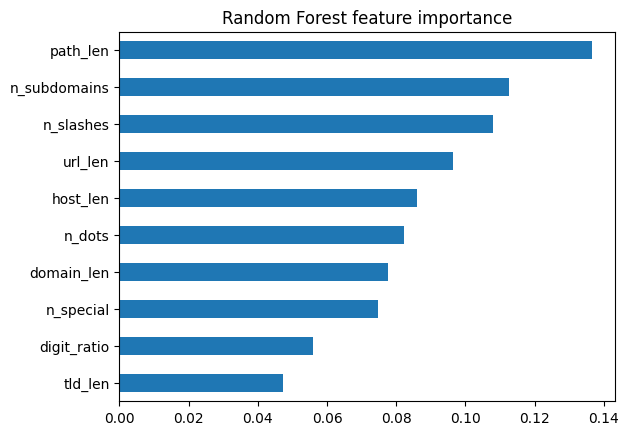

In [8]:
import matplotlib.pyplot as plt

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.round(3))
imp.head(10).plot(kind="barh").invert_yaxis()
plt.title("Random Forest feature importance")
plt.show()

In [9]:
p = rf.predict_proba(X_test)[:, 1]
for t in [0.3, 0.5, 0.7, 0.9]:
    pred = (p >= t).astype(int)
    print(f"t={t}: precision={precision_score(y_test, pred):.3f} "
          f"recall={recall_score(y_test, pred):.3f} flagged={pred.sum()}")
        

t=0.3: precision=0.770 recall=0.900 flagged=27520
t=0.5: precision=0.865 recall=0.833 flagged=22651
t=0.7: precision=0.924 recall=0.751 flagged=19141
t=0.9: precision=0.976 recall=0.628 flagged=15151


In [10]:
import joblib, json

joblib.dump(rf, "../models/url_rf.joblib", compress=3)
json.dump(list(X_train.columns), open("../models/url_feature_order.json", "w"))

def check_url(url, low=0.3, high=0.7):
    try:
        f = pd.DataFrame([extract_features(url)])[X_train.columns]
    except ValueError:
        return {"url": url, "verdict": "SUSPICIOUS (unparseable link)", "score": None}
    s = float(rf.predict_proba(f)[0, 1])
    verdict = ("DANGEROUS" if s >= high else
               "SUSPICIOUS" if s >= low else "LOOKS SAFE")
    return {"url": url, "verdict": verdict, "score": round(s, 3)}

for u in ["https://www.google.com",
          "http://sbi-kyc-update.verify-account.xyz/login",
          "http://192.168.1.5/kyc-verify.apk"]:
    print(check_url(u))

{'url': 'https://www.google.com', 'verdict': 'DANGEROUS', 'score': 0.974}
{'url': 'http://sbi-kyc-update.verify-account.xyz/login', 'verdict': 'SUSPICIOUS', 'score': 0.518}
{'url': 'http://192.168.1.5/kyc-verify.apk', 'verdict': 'DANGEROUS', 'score': 0.99}


In [2]:
import pandas as pd
features = pd.read_csv("../data/processed/url_features.csv")

tmp = features.copy()
tmp["no_path"] = tmp["path_len"] <= 1
print(tmp.groupby("no_path")["label"].agg(["mean", "count"]))

             mean   count
no_path                  
False    0.197995  468659
True     0.323131   77139
